In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.width',200,'display.max_columns',40)
sns.set_theme(style='whitegrid')
raw=pd.read_csv('SCMS_Delivery_History_Dataset_20150929.csv',encoding='latin-1')
print(raw.shape)
raw.head()

(10324, 33)


,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,PQ First Sent to Client Date,PO Sent to Vendor Date,Scheduled Delivery Date,Delivered to Client Date,Delivery Recorded Date,Product Group,Sub Classification,Vendor,Item Description,Molecule/Test Type,Brand,Dosage,Dosage Form,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,2-Jun-06,2-Jun-06,2-Jun-06,HRDT,HIV test,RANBAXY Fine Chemicals LTD.,"HIV, Reveal G3 Rapid HIV-1 Antibody Test, 30 T...","HIV, Reveal G3 Rapid HIV-1 Antibody Test",Reveal,NaN,Test kit,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,14-Nov-06,14-Nov-06,14-Nov-06,ARV,Pediatric,Aurobindo Pharma Limited,"Nevirapine 10mg/ml, oral suspension, Bottle, 2...",Nevirapine,Generic,10mg/ml,Oral suspension,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,Pre-PQ Process,Date Not Captured,27-Aug-06,27-Aug-06,27-Aug-06,HRDT,HIV test,Abbott GmbH & Co. KG,"HIV 1/2, Determine Complete HIV Kit, 100 Tests","HIV 1/2, Determine Complete HIV Kit",Determine,NaN,Test kit,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,1-Sep-06,1-Sep-06,1-Sep-06,ARV,Adult,SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LAB...,"Lamivudine 150mg, tablets, 60 Tabs",Lamivudine,Generic,150mg,Tablet,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,11-Aug-06,11-Aug-06,11-Aug-06,ARV,Adult,Aurobindo Pharma Limited,"Stavudine 30mg, capsules, 60 Caps",Stavudine,Generic,30mg,Capsule,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


In [2]:
raw.info()
print(raw.isna().sum()[raw.isna().sum()>0])

<class 'pandas.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ID                            10324 non-null  int64  
 1   Project Code                  10324 non-null  str    
 2   PQ #                          10324 non-null  str    
 3   PO / SO #                     10324 non-null  str    
 4   ASN/DN #                      10324 non-null  str    
 5   Country                       10324 non-null  str    
 6   Managed By                    10324 non-null  str    
 7   Fulfill Via                   10324 non-null  str    
 8   Vendor INCO Term              10324 non-null  str    
 9   Shipment Mode                 9964 non-null   str    
 10  PQ First Sent to Client Date  10324 non-null  str    
 11  PO Sent to Vendor Date        10324 non-null  str    
 12  Scheduled Delivery Date       10324 non-null  str    
 13  Delivered to

In [3]:
print(raw.duplicated().sum(), raw['ID'].duplicated().sum(), raw.drop(columns='ID').duplicated().sum())
df=raw.drop_duplicates(subset=[c for c in raw.columns if c!='ID']).copy()
print(df.shape)

0 0 4
(10320, 33)


In [4]:
for col in ['Freight Cost (USD)','Weight (Kilograms)']:
    num=pd.to_numeric(df[col],errors='coerce')
    print(col,num.notna().sum(),num.isna().sum())
    print(df.loc[num.isna(),col].str.replace(r'\d+','N',regex=True).value_counts(),'\n')

Freight Cost (USD) 6198 4122
Freight Cost (USD)
See DN-N (ID#:N)                      1934
Freight Included in Commodity Cost    1442
See ASN-N (ID#:N)                      507
Invoiced Separately                    239
Name: count, dtype: int64 

Weight (Kilograms) 6372 3948
Weight (Kilograms)
See DN-N (ID#:N)              1934
Weight Captured Separately    1507
See ASN-N (ID#:N)              507
Name: count, dtype: int64 



In [5]:
df['freight']=pd.to_numeric(df['Freight Cost (USD)'],errors='coerce')
df['weight']=pd.to_numeric(df['Weight (Kilograms)'],errors='coerce')
df['year']=pd.to_datetime(df['Delivered to Client Date'],format='%d-%b-%y',errors='coerce').dt.year
g=df.groupby('ASN/DN #').agg(baris=('ID','size'),n_freight=('freight','count'),n_negara=('Country','nunique'))
print(len(g), g.n_freight.max(), (g.n_negara>1).sum())
print(df['year'].value_counts().sort_index())

7030 1 0
year
2006      65
2007     671
2008    1105
2009    1192
2010    1176
2011    1049
2012    1253
2013    1239
2014    1573
2015     997
Name: count, dtype: int64


In [6]:
RULES=[('alere medical','Alere/Inverness (Japan)'),('inverness japan','Alere/Inverness (Japan)'),
 ('aurobindo','Aurobindo (India)'),('mylan','Mylan/Matrix (India)'),('hetero','Hetero (India)'),
 ('cipla','Cipla (India)'),('strides','Strides (India)'),('micro labs','Micro Labs (India)'),
 ('ranbaxy','Ranbaxy (India)'),('emcure','Emcure (India)'),('abbvie','AbbVie/Abbott (Eropa)'),
 ('trinity','Trinity Biotech (Irlandia)'),('chembio','Chembio (USA)'),('standard diag','Standard Diagnostics (Korea)'),
 ('khb','KHB (China)'),('bms','BMS (Eropa)'),('bristol','BMS (Eropa)'),('msd','MSD'),('roche','Roche'),
 ('janssen','Janssen'),('gsk','GSK'),('novartis','Novartis'),('orasure','Orasure (USA)')]
def group_site(s):
    s=str(s).lower()
    for k,v in RULES:
        if k in s: return v
    return 'Lainnya'
df['origin']=np.where(df['Fulfill Via']=='From RDC','SCMS RDC',df['Manufacturing Site'].map(group_site))
print(df['origin'].nunique())

23


In [7]:
carrier=df[df.freight.notna()&df.weight.notna()&(df.freight>0)&(df.weight>0)]
d=df[df['ASN/DN #'].isin(set(carrier['ASN/DN #']))]
dom=d.sort_values('Line Item Value',ascending=False).drop_duplicates('ASN/DN #').set_index('ASN/DN #')
car=carrier.set_index('ASN/DN #')
ship=pd.DataFrame({'sumber':dom['origin'],'tujuan':dom['Country'],'moda':dom['Shipment Mode'].fillna('Tidak tercatat'),
                   'tahun':dom['year'],'berat_kg':car['weight'],'biaya_freight_usd':car['freight']})
ship['biaya_per_kg']=ship.biaya_freight_usd/ship.berat_kg
ship=ship.reset_index().rename(columns={'ASN/DN #':'id_pengiriman'})
print(ship.shape)
ship.head()

(6174, 8)


,id_pengiriman,sumber,tujuan,moda,tahun,berat_kg,biaya_freight_usd,biaya_per_kg
0,ASN-10006,BMS (Eropa),Haiti,Air,2011,94.0,757.42,8.057660
1,ASN-10007,BMS (Eropa),Haiti,Air,2011,43.0,1082.89,25.183488
2,ASN-10062,Alere/Inverness (Japan),Haiti,Air,2011,453.0,7030.94,15.520839
3,ASN-10063,Alere/Inverness (Japan),Haiti,Air,2011,8.0,1011.60,126.450000
4,ASN-10064,Alere/Inverness (Japan),Guyana,Air,2011,205.0,6455.37,31.489610


count     6174.00
mean        38.93
std        581.78
min          0.00
1%           0.36
5%           0.82
50%          7.26
95%         67.65
99%        424.61
max      31087.70
Name: biaya_per_kg, dtype: float64
0.026 1749.3 19


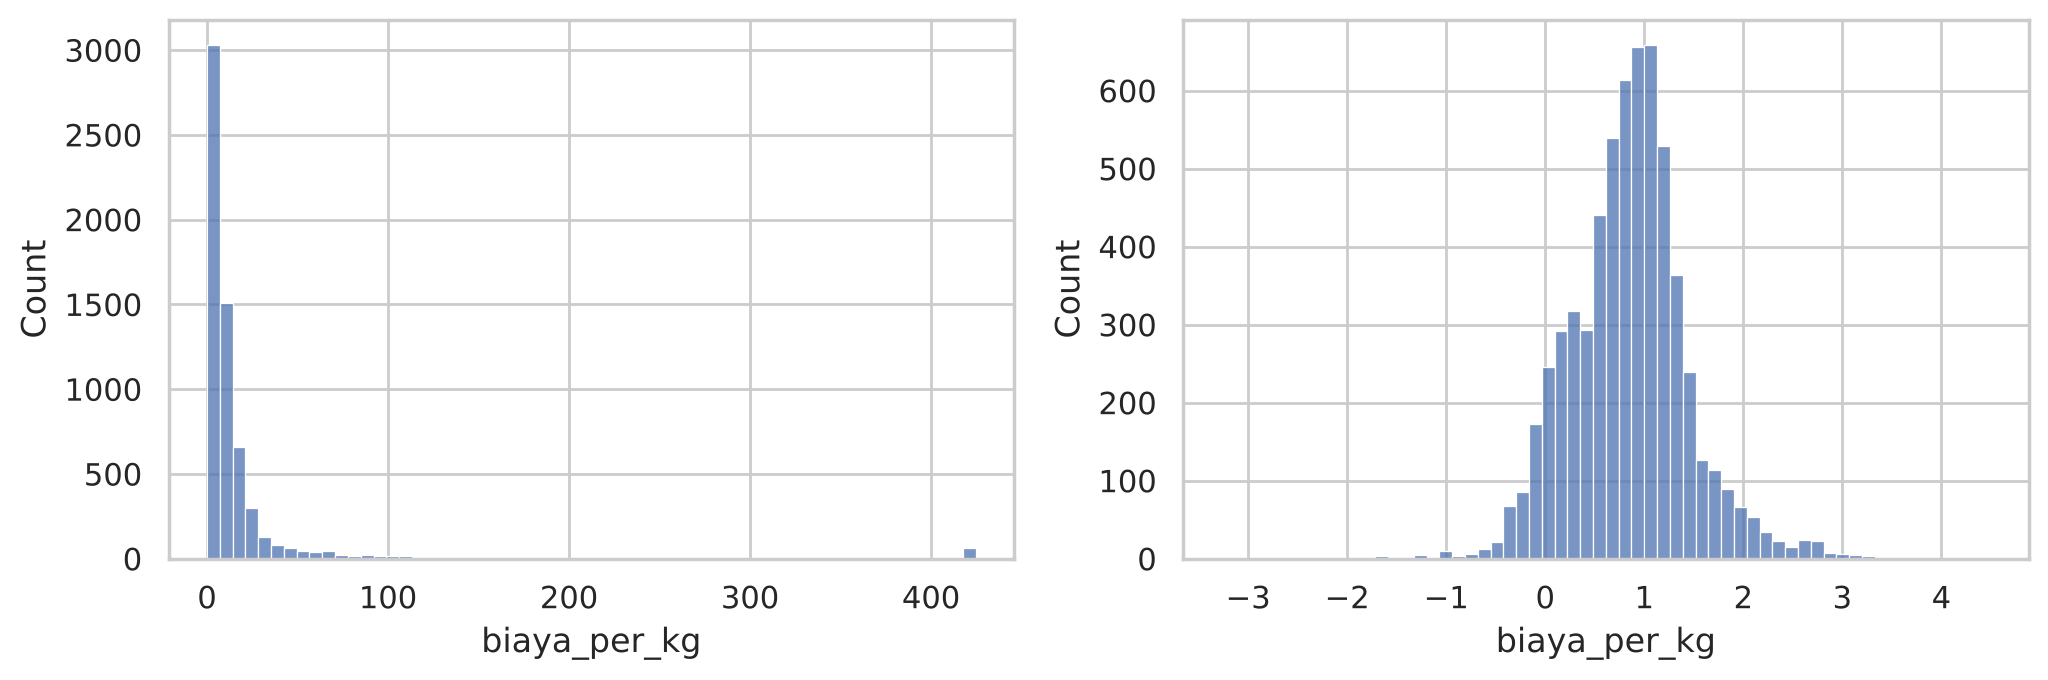

In [8]:
print(ship.biaya_per_kg.describe(percentiles=[.01,.05,.5,.95,.99]).round(2))
lg=np.log10(ship.biaya_per_kg)
q1,q3=lg.quantile([.25,.75]); iqr=q3-q1
lo,hi=q1-3*iqr,q3+3*iqr
print(round(10**lo,3),round(10**hi,1),((lg<lo)|(lg>hi)).sum())
fig,ax=plt.subplots(1,2,figsize=(12,3.5))
sns.histplot(ship.biaya_per_kg.clip(upper=ship.biaya_per_kg.quantile(.99)),bins=60,ax=ax[0])
sns.histplot(lg,bins=60,ax=ax[1])
plt.show()

In [9]:
clean=ship[(lg>=lo)&(lg<=hi)&(ship.sumber!='Lainnya')].copy()
print(len(clean),len(ship))

6037 6174


In [10]:
print(len(clean), f'{clean.berat_kg.sum():,.0f}', f'{clean.biaya_freight_usd.sum():,.0f}', round(clean.biaya_freight_usd.sum()/clean.berat_kg.sum(),3))
clean[['berat_kg','biaya_freight_usd','biaya_per_kg']].describe().round(2)

6037 19,550,180 67,933,960 3.475


,berat_kg,biaya_freight_usd,biaya_per_kg
count,6037.00,6037.00,6037.00
mean,3238.39,11252.93,20.92
std,6729.15,15881.63,73.95
min,1.00,14.36,0.04
25%,230.00,2202.02,2.97
50%,1092.00,6001.52,7.12
75%,3408.00,14547.55,14.61
max,112027.00,289653.20,1658.56


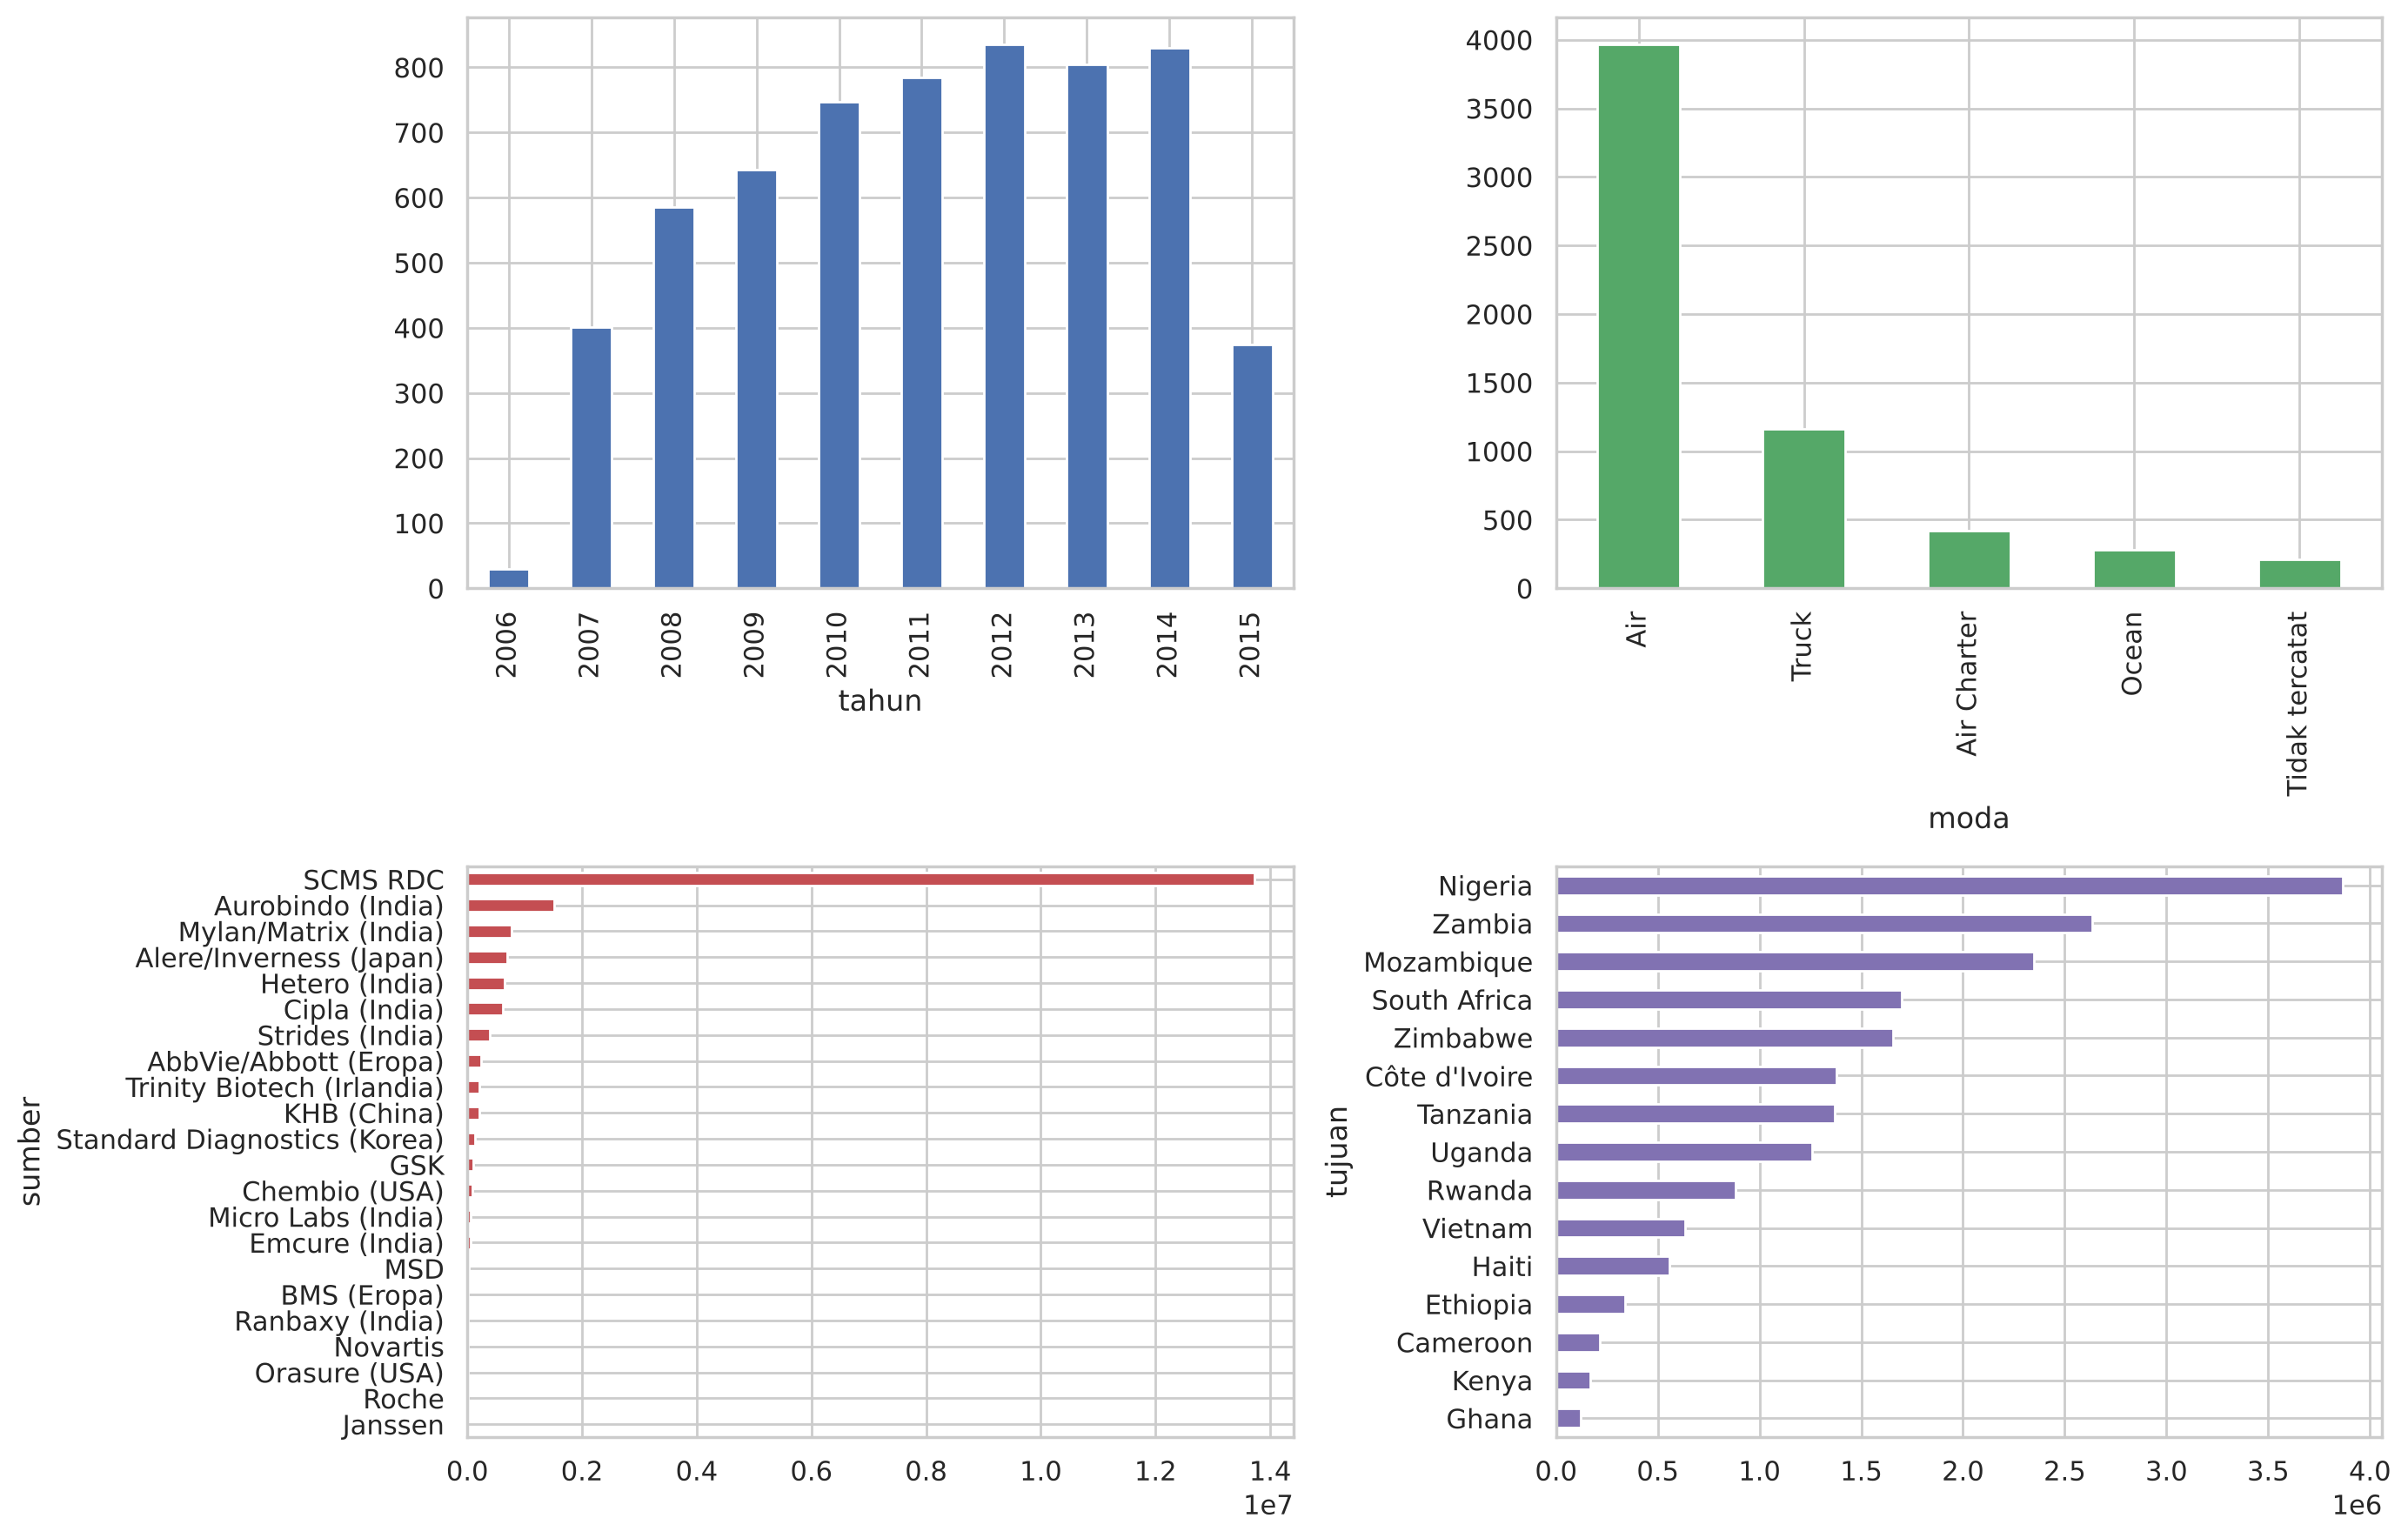

In [11]:
fig,ax=plt.subplots(2,2,figsize=(14,9))
clean.groupby('tahun').size().plot.bar(ax=ax[0,0],color='#4c72b0')
clean.moda.value_counts().plot.bar(ax=ax[0,1],color='#55a868')
clean.groupby('sumber').berat_kg.sum().sort_values().plot.barh(ax=ax[1,0],color='#c44e52')
clean.groupby('tujuan').berat_kg.sum().sort_values().tail(15).plot.barh(ax=ax[1,1],color='#8172b2')
plt.tight_layout(); plt.show()

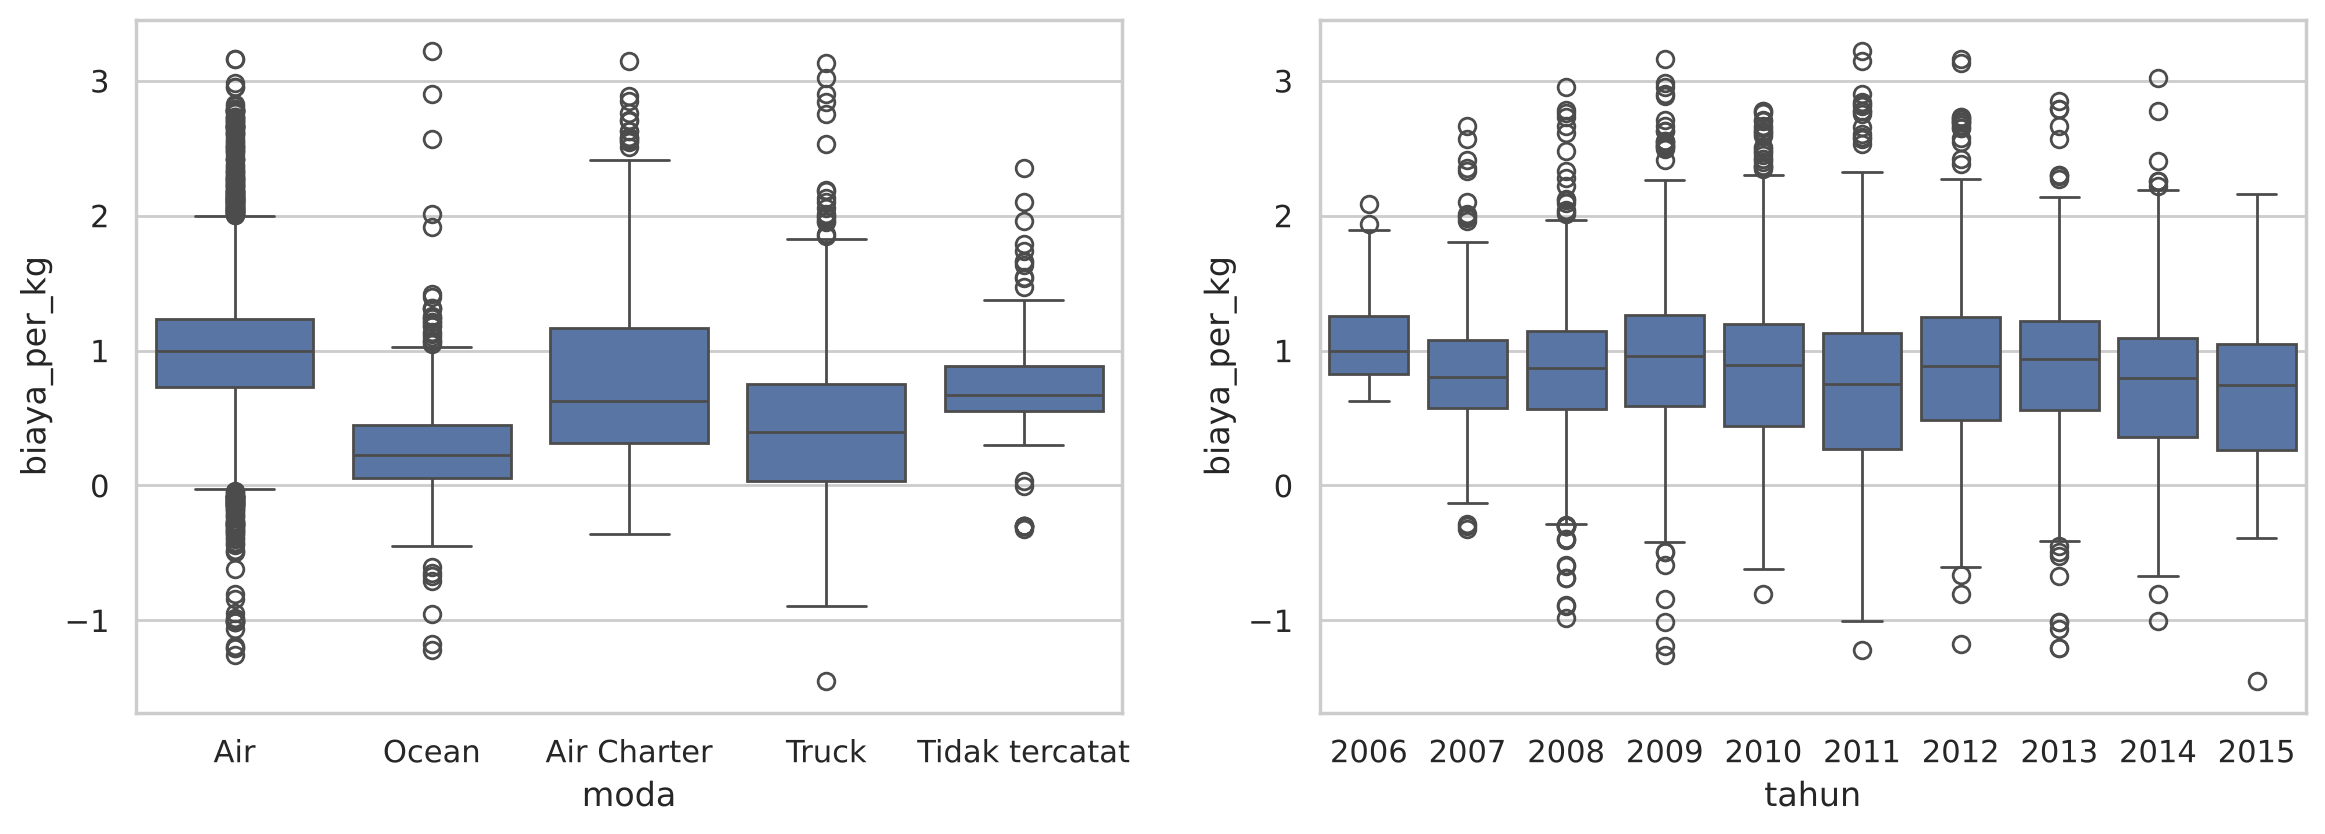

tahun
2006    7.27
2007    4.83
2008    4.21
2009    4.46
2010    4.04
2011    2.93
2012    3.58
2013    4.02
2014    3.02
2015    2.44
dtype: float64


In [12]:
fig,ax=plt.subplots(1,2,figsize=(14,4.5))
sns.boxplot(data=clean,x='moda',y=np.log10(clean.biaya_per_kg),ax=ax[0])
sns.boxplot(data=clean,x='tahun',y=np.log10(clean.biaya_per_kg),ax=ax[1])
plt.show()
print(clean.groupby('tahun').apply(lambda x:x.biaya_freight_usd.sum()/x.berat_kg.sum()).round(2))

In [13]:
supply=clean.groupby('sumber').berat_kg.sum().rename('supply_kg').sort_values(ascending=False)
demand=clean.groupby('tujuan').berat_kg.sum().rename('demand_kg').sort_values(ascending=False)
route=clean.groupby(['sumber','tujuan']).agg(jumlah_pengiriman=('id_pengiriman','size'),total_berat_kg=('berat_kg','sum'),
        total_freight_usd=('biaya_freight_usd','sum')).reset_index()
route['biaya_per_kg']=route.total_freight_usd/route.total_berat_kg
m,n=len(supply),len(demand)
print(m,n,m+n)
print(len(route),m*n,round(len(route)/(m*n),3))
print(np.isclose(supply.sum(),demand.sum()), (route.jumlah_pengiriman==1).sum())

22 38 60
258 836 0.309
True 44


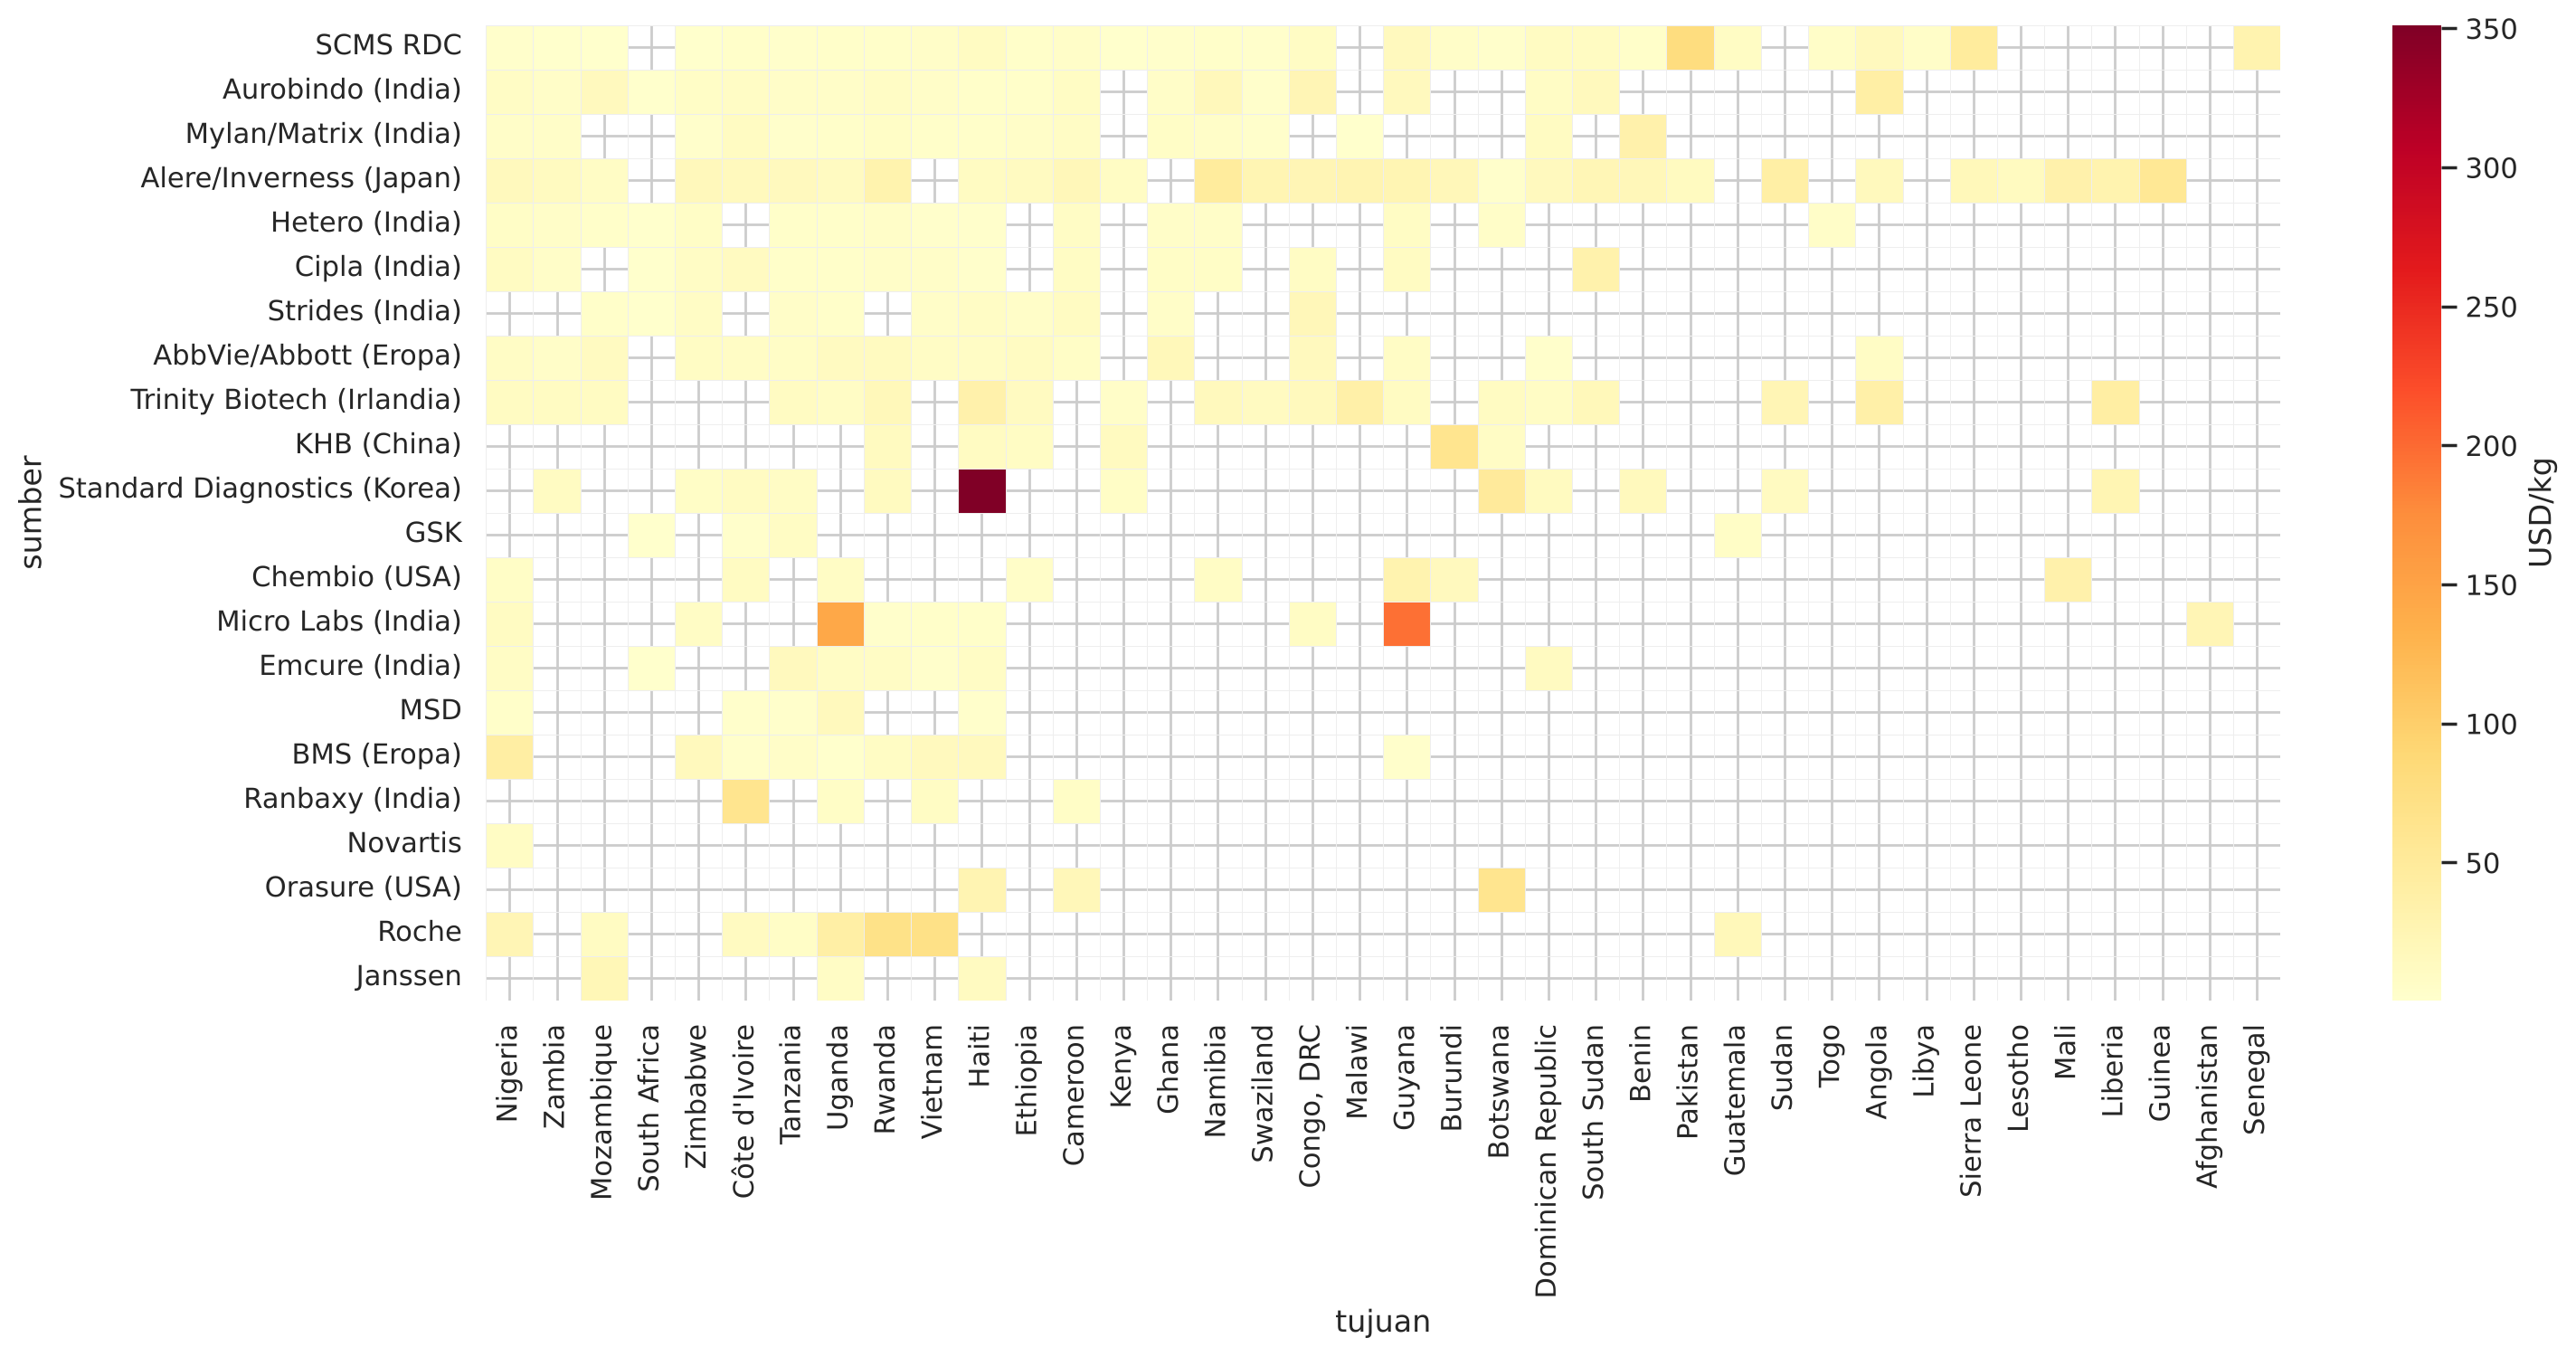

In [14]:
cost=route.pivot(index='sumber',columns='tujuan',values='biaya_per_kg').reindex(index=supply.index,columns=demand.index)
plt.figure(figsize=(16,7))
sns.heatmap(cost,cmap='YlOrRd',cbar_kws={'label':'USD/kg'},linewidths=.3,linecolor='#eee')
plt.show()

In [15]:
OUT='.'
final=clean[['sumber','tujuan','berat_kg','biaya_freight_usd']].sort_values(['sumber','tujuan']).round({'biaya_freight_usd':2})
nodes=pd.concat([supply.reset_index().rename(columns={'sumber':'node','supply_kg':'volume_kg'}).assign(tipe='Sumber'),
                 demand.reset_index().rename(columns={'tujuan':'node','demand_kg':'volume_kg'}).assign(tipe='Tujuan')])[['tipe','node','volume_kg']]
final.to_csv(f'{OUT}/scms_data_bersih.csv',index=False)
cost.round(4).to_csv(f'{OUT}/scms_matriks_biaya.csv')
nodes.to_csv(f'{OUT}/scms_node_supply_demand.csv',index=False)
print(final.shape)

(6037, 4)
